In [1]:
import os
import s3fs
import pandas as pd

fs = s3fs.S3FileSystem(
    client_kwargs={
        "endpoint_url": "https://" + os.environ["AWS_S3_ENDPOINT"]
    }
)

with fs.open("sarahliabes/diffusion/stations_2022.parquet", "rb") as f:
    df_stations = pd.read_parquet(f)

print("Nombre de stations :", len(df_stations))
print("Colonnes :", df_stations.columns.tolist())
display(df_stations.head())

Nombre de stations : 9563
Colonnes : ['id_station', 'latitude', 'longitude', 'code_postal', 'type_route', 'nb_maj_periode', 'departement']


,id_station,latitude,longitude,code_postal,type_route,nb_maj_periode,departement
0,1000001,46.201,5.198,01000,R,87,01
1,1000004,46.188,5.245,01000,R,44,01
2,1000007,46.221,5.245,01000,R,174,01
3,1000009,46.196,5.229,01000,R,82,01
4,1000012,46.201,5.200,01000,R,322,01


In [2]:
print("Nombre de stations :", len(df_stations))

print("Stations uniques :", df_stations["id_station"].nunique())

print("Départements manquants :", df_stations["departement"].isna().sum())

print("Nombre de départements représentés :", df_stations["departement"].nunique())

print("Codes des départements :")
print(sorted(df_stations["departement"].dropna().astype(str).unique()))

Nombre de stations : 9563
Stations uniques : 9563
Départements manquants : 0
Nombre de départements représentés : 96
Codes des départements :
['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '21', '22', '23', '24', '25', '26', '27', '28', '29', '2A', '2B', '30', '31', '32', '33', '34', '35', '36', '37', '38', '39', '40', '41', '42', '43', '44', '45', '46', '47', '48', '49', '50', '51', '52', '53', '54', '55', '56', '57', '58', '59', '60', '61', '62', '63', '64', '65', '66', '67', '68', '69', '70', '71', '72', '73', '74', '75', '76', '77', '78', '79', '80', '81', '82', '83', '84', '85', '86', '87', '88', '89', '90', '91', '92', '93', '94', '95']


In [3]:
import json
import urllib.request

url = (
    "https://raw.githubusercontent.com/gregoiredavid/"
    "france-geojson/master/departements-version-simplifiee.geojson"
)

with urllib.request.urlopen(url, timeout=30) as reponse:
    geo = json.load(reponse)

codes_geo = {
    x["properties"]["code"]
    for x in geo["features"]
}

codes_stations = set(df_stations["departement"].dropna().astype(str))

print("Codes présents dans les deux fichiers :", len(codes_geo & codes_stations))
print("Codes stations absents du GeoJSON :", sorted(codes_stations - codes_geo))
print("Codes GeoJSON absents des stations :", sorted(codes_geo - codes_stations))
print("Correspondance parfaite :", codes_geo == codes_stations)

Codes présents dans les deux fichiers : 96
Codes stations absents du GeoJSON : []
Codes GeoJSON absents des stations : []
Correspondance parfaite : True


In [4]:
import geopandas as gpd

# Transformer le GeoJSON en tableau géographique
departements = gpd.GeoDataFrame.from_features(
    geo["features"], crs="EPSG:4326"
)[["code", "geometry"]]

# Transformer les stations en points GPS
stations_geo = gpd.GeoDataFrame(
    df_stations.copy(),
    geometry=gpd.points_from_xy(
        df_stations["longitude"],
        df_stations["latitude"]
    ),
    crs="EPSG:4326"
)

# Trouver dans quel département se situe chaque point
resultat = gpd.sjoin(
    stations_geo,
    departements,
    how="left",
    predicate="within"
)

# Vérifier les correspondances
hors_carte = resultat["code"].isna()
erreurs = (~hors_carte) & (
    resultat["departement"] != resultat["code"]
)

print("Stations étudiées :", len(df_stations))
print("Stations hors contours :", hors_carte.sum())
print("Départements différents :", erreurs.sum())

display(
    resultat.loc[
        hors_carte | erreurs,
        ["id_station", "departement", "code", "latitude", "longitude"]
    ].head(10)
)

Stations étudiées : 9563
Stations hors contours : 13
Départements différents : 41


,id_station,departement,code,latitude,longitude
92,1590002,01,39,46.32500,5.67200
451,6400004,06,NaN,43.54700,7.04600
452,6400005,06,NaN,43.54738,7.04418
480,6600008,06,NaN,43.57400,7.12400
916,13008014,13,NaN,43.24300,5.36900
1115,13620002,13,NaN,43.32800,5.15000
1229,14380002,14,50,48.93800,-1.03300
1611,19340003,19,63,45.62400,2.48100
1623,19600003,19,46,45.03300,1.50300
1649,20130002,2A,NaN,42.13400,8.59800


In [5]:
# Télécharger les contours détaillés
url_detail = (
    "https://raw.githubusercontent.com/gregoiredavid/"
    "france-geojson/master/departements.geojson"
)

with urllib.request.urlopen(url_detail, timeout=60) as reponse:
    geo_detail = json.load(reponse)

departements_detail = gpd.GeoDataFrame.from_features(
    geo_detail["features"], crs="EPSG:4326"
)[["code", "geometry"]]

# Refaire la jointure spatiale
resultat_detail = gpd.sjoin(
    stations_geo,
    departements_detail,
    how="left",
    predicate="within"
)

hors_detail = resultat_detail["code"].isna()

erreurs_detail = (~hors_detail) & (
    resultat_detail["departement"] != resultat_detail["code"]
)

print("Stations hors contours :", hors_detail.sum())
print("Départements différents :", erreurs_detail.sum())
print("Stations correctement associées :",
      (~hors_detail & ~erreurs_detail).sum())

Stations hors contours : 6
Départements différents : 18
Stations correctement associées : 9539


In [6]:
anomalies = resultat_detail.loc[
    hors_detail | erreurs_detail,
    [
        "id_station",
        "code_postal",
        "departement",
        "code",
        "latitude",
        "longitude"
    ]
].copy()

print("Nombre de lignes après jointure :", len(resultat_detail))
print("Nombre de stations initiales :", len(df_stations))
print("Nombre d'anomalies :", len(anomalies))

display(anomalies)

Nombre de lignes après jointure : 9563
Nombre de stations initiales : 9563
Nombre d'anomalies : 24


,id_station,code_postal,departement,code,latitude,longitude
92,1590002,01590,01,39,46.325000,5.672000
463,6500008,06500,06,NaN,43.784000,7.521000
1229,14380002,14380,14,50,48.938000,-1.033000
1611,19340003,19340,19,63,45.624000,2.481000
1623,19600003,19600,19,46,45.033000,1.503000
1730,20260001,20260,2B,NaN,42.572000,8.759000
1825,21310004,21310,21,70,47.356000,5.513000
2060,24240003,24240,24,50,49.304605,-1.161372
3061,33220001,33220,33,24,44.845000,0.181000
3062,33220004,33220,33,24,44.842852,0.205146


In [7]:
# Comparer les codes postaux aux départements déclarés
anomalies["dep_postal"] = (
    anomalies["code_postal"].astype(str).str.zfill(5).str[:2]
)

# On traite la Corse séparément (codes 2A et 2B)
hors_corse = anomalies[
    ~anomalies["departement"].isin(["2A", "2B"])
].copy()

hors_corse["accord_postal"] = (
    hors_corse["dep_postal"] == hors_corse["departement"]
)

print("Anomalies hors Corse :", len(hors_corse))
print("Code postal cohérent :", hors_corse["accord_postal"].sum())
print("Code postal incohérent :", (~hors_corse["accord_postal"]).sum())

display(hors_corse[
    ["id_station", "code_postal", "departement", "code", "accord_postal"]
])

Anomalies hors Corse : 23
Code postal cohérent : 23
Code postal incohérent : 0


,id_station,code_postal,departement,code,accord_postal
92,1590002,01590,01,39,True
463,6500008,06500,06,NaN,True
1229,14380002,14380,14,50,True
1611,19340003,19340,19,63,True
1623,19600003,19600,19,46,True
1825,21310004,21310,21,70,True
2060,24240003,24240,24,50,True
3061,33220001,33220,33,24,True
3062,33220004,33220,33,24,True
4077,41600003,41600,41,45,True


In [8]:

from geographie import verifier_departements_stations

anomalies_test = verifier_departements_stations(df_stations)

print("Test terminé !")


Stations analysées : 9563
Stations hors contours : 6
Départements différents : 18
Total des anomalies : 24
Test terminé !


In [9]:

from distances import calculer_distances_stations

# Convertir les données de Sarah en liste
stations = df_stations.to_dict(orient="records")

# Calculer les distances
resultats_distances = calculer_distances_stations(stations)

# Afficher les résultats
print("Nombre de stations analysées :", len(resultats_distances))

import pandas as pd
df_distances = pd.DataFrame(resultats_distances)

display(df_distances.head(10))


Nombre de stations analysées : 9563


,id_station,site_proche,distance_km
0,1000001,Feyzin,64.90
1,1000004,Feyzin,65.24
2,1000007,Feyzin,68.49
3,1000009,Feyzin,65.45
4,1000012,Feyzin,64.96
5,1000013,Feyzin,66.22
6,1090001,Feyzin,47.42
7,1100001,Feyzin,92.96
8,1100002,Feyzin,89.23
9,1100004,Feyzin,91.84


In [10]:

# Vérification des résultats
print("Nombre de stations :", len(df_distances))
print("Stations uniques :", df_distances["id_station"].nunique())
print("Distances manquantes :", df_distances["distance_km"].isna().sum())

# Statistiques descriptives
print("\nSTATISTIQUES DES DISTANCES (KM)")
print(
    df_distances["distance_km"]
    .describe(percentiles=[0.25, 0.5, 0.75, 0.9])
    .round(2)
)

# Répartition des stations entre les sites
print("\nNOMBRE DE STATIONS PAR SITE LE PLUS PROCHE")
print(df_distances["site_proche"].value_counts())


Nombre de stations : 9563
Stations uniques : 9563
Distances manquantes : 0

STATISTIQUES DES DISTANCES (KM)
count    9563.00
mean      169.80
std       104.62
min         0.44
25%        88.68
50%       149.43
75%       241.20
90%       327.55
max       470.22
Name: distance_km, dtype: float64

NOMBRE DE STATIONS PAR SITE LE PLUS PROCHE
site_proche
Feyzin         2771
Donges         1889
Port-Jerome    1604
Fos-sur-Mer    1300
Flandres        907
La Mede         735
Gonfreville     357
Name: count, dtype: int64


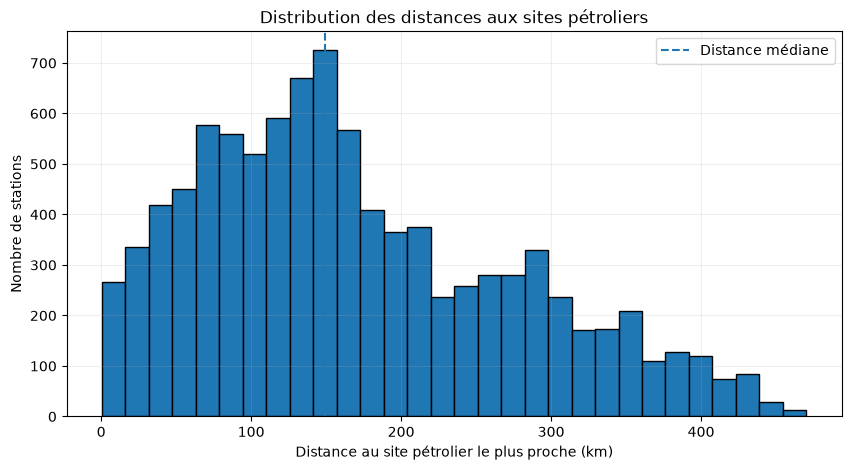

In [11]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    df_distances["distance_km"],
    bins=30,
    edgecolor="black"
)

plt.axvline(
    df_distances["distance_km"].median(),
    linestyle="--",
    label="Distance médiane"
)

plt.xlabel("Distance au site pétrolier le plus proche (km)")
plt.ylabel("Nombre de stations")
plt.title("Distribution des distances aux sites pétroliers")
plt.legend()
plt.grid(alpha=0.2)

plt.show()


In [12]:

from pathlib import Path

# Créer le dossier de résultats
Path("data/traite").mkdir(parents=True, exist_ok=True)

# Enregistrer les distances
df_distances.to_csv(
    "data/traite/distances_stations_2022.csv",
    index=False
)

print("Fichier enregistré !")
print("Nombre de stations :", len(df_distances))


Fichier enregistré !
Nombre de stations : 9563


In [13]:

# Charger les données de pénuries de Sarah
with fs.open("sarahliabes/diffusion/ruptures_sept_nov_2022.parquet", "rb") as f:
    df_ruptures = pd.read_parquet(f)

# Examiner leur structure
print("Nombre de lignes :", len(df_ruptures))
print("Colonnes :", df_ruptures.columns.tolist())

print("\nTypes des variables :")
print(df_ruptures.dtypes)

display(df_ruptures.head(10))


Nombre de lignes : 106325
Colonnes : ['id_station', 'carburant', 'debut', 'fin', 'departement', 'latitude', 'longitude', 'type_route', 'duree_heures', 'fin_connue']

Types des variables :
id_station                 str
carburant                  str
debut           datetime64[ns]
fin             datetime64[ns]
departement                str
latitude               float64
longitude              float64
type_route                 str
duree_heures           float64
fin_connue                bool
dtype: object


,id_station,carburant,debut,fin,departement,latitude,longitude,type_route,duree_heures,fin_connue
0,1000001,SP95,2022-10-11 08:31:05,2022-10-11 17:10:56,01,46.201,5.198,R,8.664167,True
1,1000001,SP95,2022-10-10 08:45:24,2022-10-11 07:33:21,01,46.201,5.198,R,22.799167,True
2,1000001,SP95,2022-10-27 09:28:54,2022-11-02 07:52:47,01,46.201,5.198,R,142.398056,True
3,1000001,SP98,2022-11-17 14:56:40,2022-11-21 08:43:51,01,46.201,5.198,R,89.786389,True
4,1000001,SP95,2022-11-17 14:56:40,2022-11-21 08:43:51,01,46.201,5.198,R,89.786389,True
5,1000001,Gazole,2022-10-11 08:31:04,2022-10-11 17:10:55,01,46.201,5.198,R,8.664167,True
6,1000001,Gazole,2022-10-19 07:31:31,2022-10-21 07:50:18,01,46.201,5.198,R,48.313056,True
7,1000001,Gazole,2022-11-02 07:53:27,2022-11-02 11:35:32,01,46.201,5.198,R,3.701389,True
8,1000001,SP98,2022-11-02 07:53:27,2022-11-02 11:35:32,01,46.201,5.198,R,3.701389,True
9,1000001,SP98,2022-11-03 08:24:51,2022-11-15 14:16:10,01,46.201,5.198,R,293.855278,True


In [14]:

# Préparer les deux tableaux
ruptures = df_ruptures.copy()
distances = df_distances.copy()

# Harmoniser les identifiants des stations
ruptures["id_station"] = ruptures["id_station"].astype(str)
distances["id_station"] = distances["id_station"].astype(str)

# Ajouter la distance à chaque épisode de rupture
df_analyse = ruptures.merge(
    distances[["id_station", "site_proche", "distance_km"]],
    on="id_station",
    how="left",
    validate="many_to_one"
)

# Vérifier la jointure
print("Ruptures initiales :", len(ruptures))
print("Lignes après jointure :", len(df_analyse))
print("Distances manquantes :", df_analyse["distance_km"].isna().sum())
print("Stations distinctes touchées :", df_analyse["id_station"].nunique())

# Afficher un aperçu
display(
    df_analyse[
        ["id_station", "carburant", "debut",
         "duree_heures", "site_proche", "distance_km"]
    ].head(10)
)


Ruptures initiales : 106325
Lignes après jointure : 106325
Distances manquantes : 0
Stations distinctes touchées : 7454


,id_station,carburant,debut,duree_heures,site_proche,distance_km
0,1000001,SP95,2022-10-11 08:31:05,8.664167,Feyzin,64.9
1,1000001,SP95,2022-10-10 08:45:24,22.799167,Feyzin,64.9
2,1000001,SP95,2022-10-27 09:28:54,142.398056,Feyzin,64.9
3,1000001,SP98,2022-11-17 14:56:40,89.786389,Feyzin,64.9
4,1000001,SP95,2022-11-17 14:56:40,89.786389,Feyzin,64.9
5,1000001,Gazole,2022-10-11 08:31:04,8.664167,Feyzin,64.9
6,1000001,Gazole,2022-10-19 07:31:31,48.313056,Feyzin,64.9
7,1000001,Gazole,2022-11-02 07:53:27,3.701389,Feyzin,64.9
8,1000001,SP98,2022-11-02 07:53:27,3.701389,Feyzin,64.9
9,1000001,SP98,2022-11-03 08:24:51,293.855278,Feyzin,64.9


In [15]:

# Une ligne par station
stations_analyse = df_distances.copy()
stations_analyse["id_station"] = stations_analyse["id_station"].astype(str)

# Identifier les stations ayant au moins une rupture recensée
ids_rupture = set(df_ruptures["id_station"].astype(str))

stations_analyse["rupture_observee"] = (
    stations_analyse["id_station"].isin(ids_rupture)
)

# Diviser les stations en 4 groupes selon leur distance
stations_analyse["groupe_distance"] = pd.qcut(
    stations_analyse["distance_km"],
    q=4,
    labels=["Q1 - Proches", "Q2", "Q3", "Q4 - Eloignees"]
)

# Calculer la proportion de stations avec une rupture
bilan = stations_analyse.groupby(
    "groupe_distance", observed=True
).agg(
    nombre_stations=("id_station", "size"),
    stations_avec_rupture=("rupture_observee", "sum"),
    distance_moyenne_km=("distance_km", "mean"),
    proportion_rupture=("rupture_observee", "mean")
)

bilan["pourcentage_rupture"] = (
    bilan["proportion_rupture"] * 100
)

display(bilan[[
    "nombre_stations",
    "stations_avec_rupture",
    "distance_moyenne_km",
    "pourcentage_rupture"
]].round(2))


,nombre_stations,stations_avec_rupture,distance_moyenne_km,pourcentage_rupture
groupe_distance,,,,
Q1 - Proches,2391,2002,51.13,83.73
Q2,2391,1944,121.15,81.30
Q3,2390,1878,187.10,78.58
Q4 - Eloignees,2391,1630,319.82,68.17


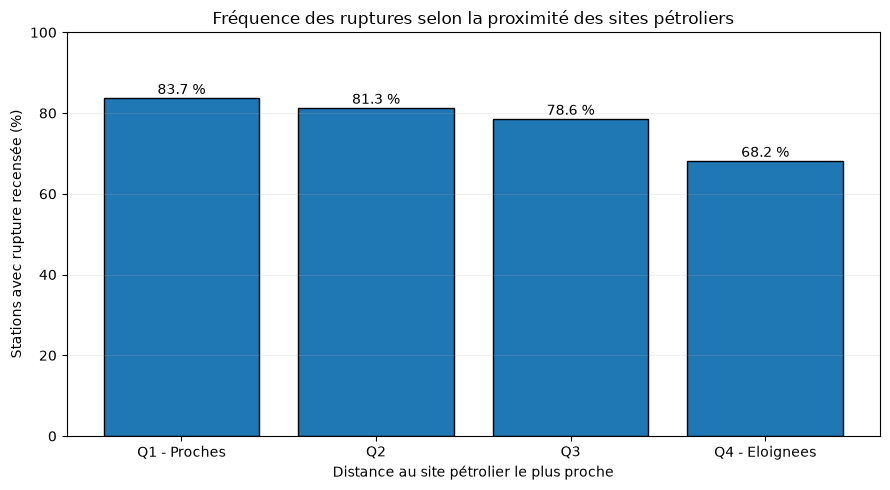

In [16]:

import matplotlib.pyplot as plt

# Pourcentage de stations avec rupture par groupe
taux = bilan["pourcentage_rupture"]

plt.figure(figsize=(9, 5))

barres = plt.bar(
    taux.index.astype(str),
    taux.values,
    edgecolor="black"
)

# Afficher les pourcentages au-dessus des barres
for barre, valeur in zip(barres, taux.values):
    plt.text(
        barre.get_x() + barre.get_width() / 2,
        valeur + 1,
        f"{valeur:.1f} %",
        ha="center"
    )

plt.xlabel("Distance au site pétrolier le plus proche")
plt.ylabel("Stations avec rupture recensée (%)")
plt.title("Fréquence des ruptures selon la proximité des sites pétroliers")
plt.ylim(0, 100)
plt.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


In [17]:

# Sélectionner les ruptures ayant commencé en octobre 2022
ruptures_octobre = df_ruptures.copy()

ruptures_octobre["debut"] = pd.to_datetime(
    ruptures_octobre["debut"]
)

ruptures_octobre = ruptures_octobre[
    (ruptures_octobre["debut"] >= "2022-10-01")
    & (ruptures_octobre["debut"] < "2022-11-01")
].copy()

# Harmoniser les identifiants
ruptures_octobre["id_station"] = (
    ruptures_octobre["id_station"].astype(str)
)

# Première rupture commencée en octobre pour chaque station
premieres_ruptures = (
    ruptures_octobre.groupby("id_station")["debut"]
    .min()
    .reset_index(name="premiere_rupture")
)

# Rattacher ces dates aux 9563 stations
stations_dates = stations_analyse.merge(
    premieres_ruptures,
    on="id_station",
    how="left",
    validate="one_to_one"
)

# Comparer les dates selon la distance
bilan_dates = stations_dates.groupby(
    "groupe_distance", observed=True
).agg(
    nombre_stations=("id_station", "size"),
    stations_avec_rupture=("premiere_rupture", "count"),
    date_mediane=("premiere_rupture", "median")
)

display(bilan_dates)


,nombre_stations,stations_avec_rupture,date_mediane
groupe_distance,,,
Q1 - Proches,2391,1937,2022-10-07 11:15:53.000
Q2,2391,1868,2022-10-08 16:13:34.500
Q3,2390,1804,2022-10-08 17:58:59.000
Q4 - Eloignees,2391,1532,2022-10-09 08:58:27.000


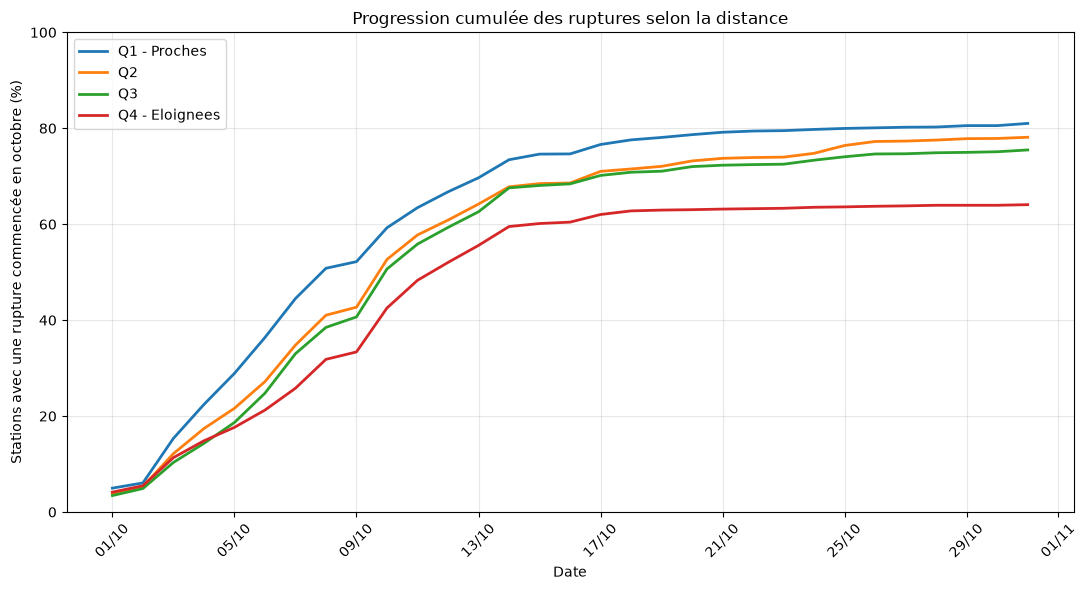

In [18]:

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import pandas as pd

jours = pd.date_range("2022-10-01", "2022-10-31")

plt.figure(figsize=(11, 6))

for groupe in stations_dates["groupe_distance"].cat.categories:

    sous_groupe = stations_dates[
        stations_dates["groupe_distance"] == groupe
    ]

    dates_ruptures = sous_groupe["premiere_rupture"].dropna()

    proportions = [
        (dates_ruptures < jour + pd.Timedelta(days=1)).sum()
        / len(sous_groupe) * 100
        for jour in jours
    ]

    plt.plot(
        jours,
        proportions,
        label=groupe,
        linewidth=2
    )

plt.xlabel("Date")
plt.ylabel("Stations avec une rupture commencée en octobre (%)")
plt.title("Progression cumulée des ruptures selon la distance")
plt.legend()
plt.grid(alpha=0.3)
plt.ylim(0, 100)

plt.gca().xaxis.set_major_formatter(
    mdates.DateFormatter("%d/%m")
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [19]:

# Ajouter les groupes de distance aux ruptures
ruptures_groupes = df_analyse.merge(
    stations_analyse[["id_station", "groupe_distance"]],
    on="id_station",
    how="left",
    validate="many_to_one"
)

# Identifier le mois de début de chaque rupture
ruptures_groupes["mois"] = (
    pd.to_datetime(ruptures_groupes["debut"])
    .dt.to_period("M")
    .astype(str)
)

# Garder septembre et octobre 2022
ruptures_groupes = ruptures_groupes[
    ruptures_groupes["mois"].isin(["2022-09", "2022-10"])
]

# Compter les débuts de rupture par groupe et par mois
comptage = (
    ruptures_groupes.groupby(
        ["groupe_distance", "mois"],
        observed=True
    ).size().unstack(fill_value=0)
)

# Ramener au nombre de stations de chaque groupe
effectifs = stations_analyse.groupby(
    "groupe_distance", observed=True
).size()

taux_mensuels = comptage.div(effectifs, axis=0)

print("Nombre de débuts de rupture par station :")
display(taux_mensuels.round(2))


Nombre de débuts de rupture par station :


mois,2022-09,2022-10
groupe_distance,,
Q1 - Proches,2.14,7.10
Q2,2.01,6.16
Q3,1.79,6.13
Q4 - Eloignees,2.22,5.10


In [20]:

# Nombre moyen de ruptures commencées par station et par jour
taux_journaliers = taux_mensuels.copy()

taux_journaliers["2022-09"] /= 30
taux_journaliers["2022-10"] /= 31

# Exprimer pour 100 stations et par jour
taux_journaliers *= 100

# Variation entre septembre et octobre
taux_journaliers["variation"] = (
    taux_journaliers["2022-10"]
    - taux_journaliers["2022-09"]
)

print("Débuts de rupture par jour pour 100 stations :")
display(taux_journaliers.round(2))

# Écart d'évolution entre les groupes extrêmes
ecart = (
    taux_journaliers.loc["Q1 - Proches", "variation"]
    - taux_journaliers.loc["Q4 - Eloignees", "variation"]
)

print("\nÉcart des évolutions Q1 - Q4 :", round(ecart, 2))


Débuts de rupture par jour pour 100 stations :


mois,2022-09,2022-10,variation
groupe_distance,,,
Q1 - Proches,7.15,22.91,15.76
Q2,6.71,19.86,13.15
Q3,5.97,19.79,13.82
Q4 - Eloignees,7.40,16.44,9.04



Écart des évolutions Q1 - Q4 : 6.73


Première rupture enregistrée : 2022-09-01 05:06:26


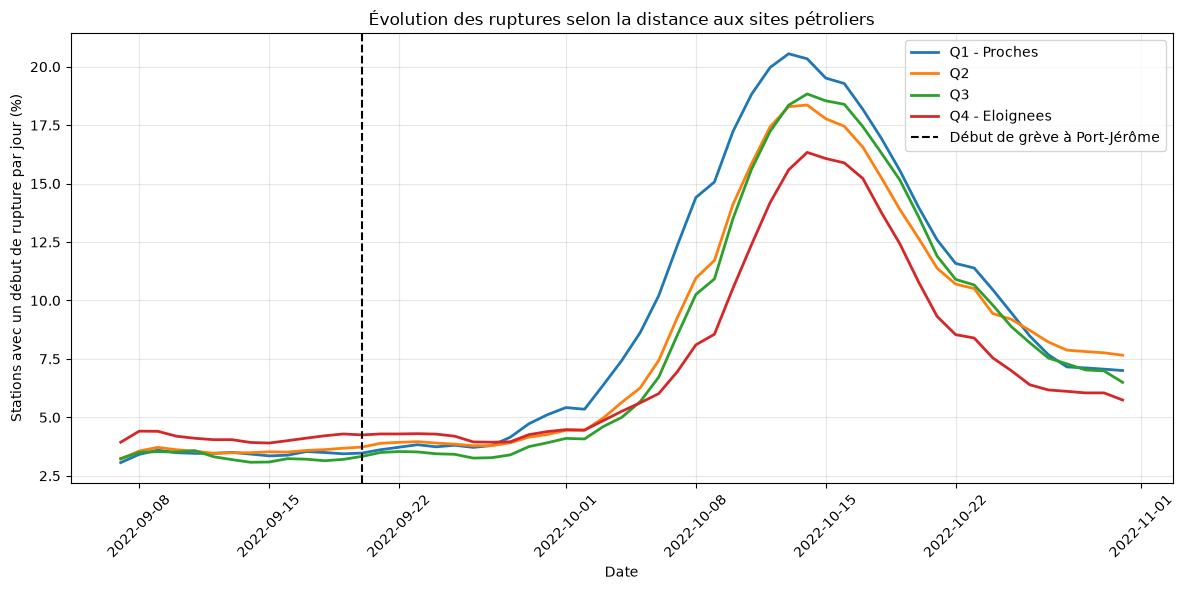

In [21]:

import pandas as pd
import matplotlib.pyplot as plt

# Une station compte au maximum une fois par jour
episodes = df_analyse[["id_station", "debut"]].copy()

episodes["id_station"] = episodes["id_station"].astype(str)
episodes["date"] = pd.to_datetime(episodes["debut"]).dt.normalize()

episodes = episodes[
    episodes["date"].between("2022-09-01", "2022-10-31")
].drop_duplicates(["id_station", "date"])

# Ajouter les groupes de distance
episodes = episodes.merge(
    stations_analyse[["id_station", "groupe_distance"]],
    on="id_station",
    how="left",
    validate="many_to_one"
)

# Nombre de stations par groupe
effectifs = stations_analyse.groupby(
    "groupe_distance", observed=True
).size()

# Débuts de rupture par jour
comptage_journalier = episodes.groupby(
    ["date", "groupe_distance"], observed=True
).size().unstack(fill_value=0)

jours = pd.date_range("2022-09-01", "2022-10-31")

# Pourcentage de stations avec un début de rupture par jour
taux_journalier = (
    comptage_journalier
    .reindex(index=jours, columns=effectifs.index, fill_value=0)
    .div(effectifs, axis=1) * 100
)

# Moyenne mobile sur 7 jours
taux_lisse = taux_journalier.rolling(
    7, min_periods=7
).mean()

print("Première rupture enregistrée :", df_ruptures["debut"].min())

# Graphique
plt.figure(figsize=(12, 6))

for groupe in taux_lisse.columns:
    plt.plot(
        taux_lisse.index,
        taux_lisse[groupe],
        label=groupe,
        linewidth=2
    )

plt.axvline(
    pd.Timestamp("2022-09-20"),
    color="black",
    linestyle="--",
    label="Début de grève à Port-Jérôme"
)

plt.xlabel("Date")
plt.ylabel("Stations avec un début de rupture par jour (%)")
plt.title("Évolution des ruptures selon la distance aux sites pétroliers")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


Écart moyen Q1-Q4 avant : -0.64
Écart moyen Q1-Q4 pendant : 4.8
Différence des écarts : 5.45


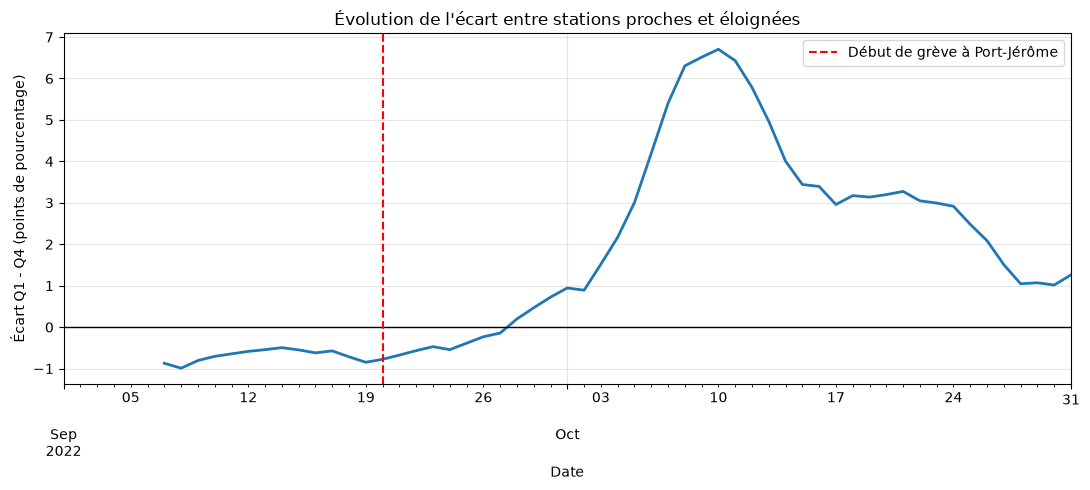

In [22]:

# Écart quotidien entre stations proches et éloignées
ecart_journalier = (
    taux_journalier["Q1 - Proches"]
    - taux_journalier["Q4 - Eloignees"]
)

# Période de référence
avant = ecart_journalier.loc[
    "2022-09-08":"2022-09-19"
].mean()

# Période de crise
crise = ecart_journalier.loc[
    "2022-10-05":"2022-10-18"
].mean()

# Comparaison descriptive
print("Écart moyen Q1-Q4 avant :", round(avant, 2))
print("Écart moyen Q1-Q4 pendant :", round(crise, 2))
print("Différence des écarts :", round(crise - avant, 2))

# Visualiser l'écart dans le temps
plt.figure(figsize=(11, 5))

ecart_journalier.rolling(
    7, min_periods=7
).mean().plot(linewidth=2)

plt.axhline(0, color="black", linewidth=1)

plt.axvline(
    pd.Timestamp("2022-09-20"),
    color="red",
    linestyle="--",
    label="Début de grève à Port-Jérôme"
)

plt.ylabel("Écart Q1 - Q4 (points de pourcentage)")
plt.xlabel("Date")
plt.title("Évolution de l'écart entre stations proches et éloignées")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [23]:

from pathlib import Path

# Dossier des résultats
dossier = Path("resultats")
dossier.mkdir(exist_ok=True)

# Sauvegarder le tableau des distances et ruptures
df_analyse.to_csv(
    dossier / "analyse_distances_ruptures.csv",
    index=False
)

# Sauvegarder l'évolution quotidienne par groupe
taux_journalier.to_csv(
    dossier / "evolution_quotidienne.csv",
    index_label="date"
)

# Sauvegarder les comparaisons septembre-octobre
taux_journaliers.to_csv(
    dossier / "comparaison_mensuelle.csv"
)

print("Résultats sauvegardés !")
print("Nombre d'épisodes :", len(df_analyse))
print("Fichiers créés :", len(list(dossier.glob("*.csv"))))


Résultats sauvegardés !
Nombre d'épisodes : 106325
Fichiers créés : 3


In [24]:

from zipfile import ZipFile, ZIP_DEFLATED
from pathlib import Path

fichiers = [
    Path("verification_stations.ipynb"),
    Path("distances.py"),
    Path("geographie.py"),
    Path("data/traite/distances_stations_2022.csv")
]

fichiers += list(Path("resultats").glob("*.csv"))

with ZipFile("sauvegarde_analyse_H1.zip", "w", ZIP_DEFLATED) as archive:
    for fichier in fichiers:
        if fichier.is_file():
            archive.write(fichier)

print("Archive créée avec succès !")
print("Fichiers sauvegardés :", len(fichiers))


Archive créée avec succès !
Fichiers sauvegardés : 7


Nombre de stations analysées : 7141
Corrélation de Spearman : 0.0647


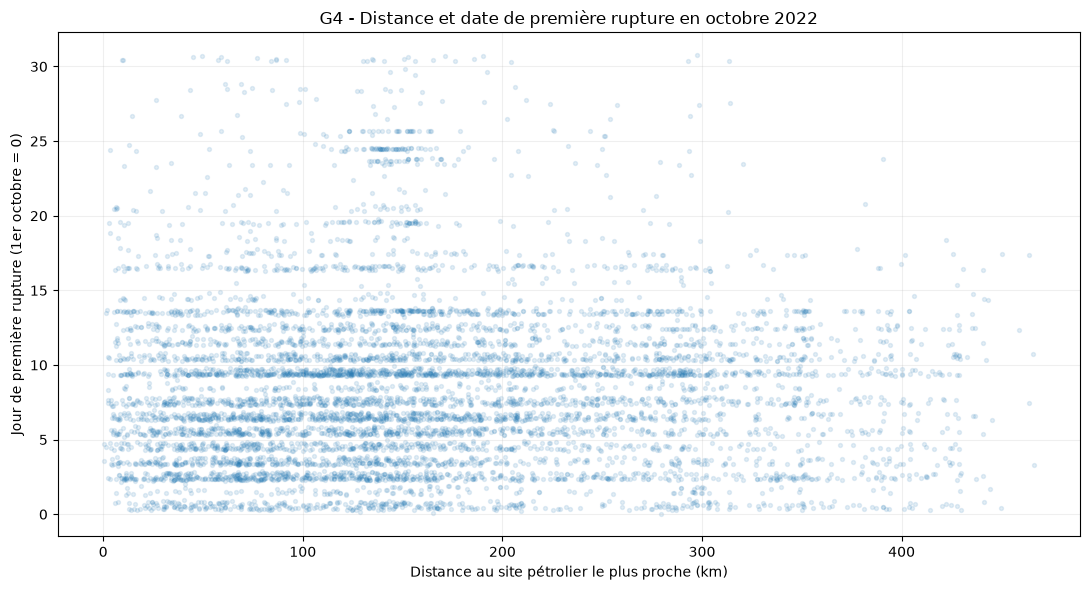

In [25]:

import pandas as pd
import matplotlib.pyplot as plt

# Garder les stations avec une rupture commencée en octobre
g4 = stations_dates.dropna(
    subset=["premiere_rupture", "distance_km"]
).copy()

# Convertir la date en nombre de jours depuis le 1er octobre
g4["jour_rupture"] = (
    g4["premiere_rupture"] - pd.Timestamp("2022-10-01")
).dt.total_seconds() / 86400

# Corrélation de Spearman
rho = g4["distance_km"].corr(
    g4["jour_rupture"],
    method="spearman"
)

print("Nombre de stations analysées :", len(g4))
print("Corrélation de Spearman :", round(rho, 4))

# Nuage de points
plt.figure(figsize=(11, 6))

plt.scatter(
    g4["distance_km"],
    g4["jour_rupture"],
    alpha=0.12,
    s=8
)

plt.xlabel("Distance au site pétrolier le plus proche (km)")
plt.ylabel("Jour de première rupture (1er octobre = 0)")
plt.title("G4 - Distance et date de première rupture en octobre 2022")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [26]:

from scipy.stats import spearmanr

rho, p_value = spearmanr(
    g4["distance_km"],
    g4["jour_rupture"]
)

print("Nombre de stations :", len(g4))
print("Coefficient de Spearman :", round(rho, 4))
print("P-value :", p_value)

if p_value < 0.05:
    print("Corrélation statistiquement significative à 5 %")
else:
    print("Corrélation non significative à 5 %")


Nombre de stations : 7141
Coefficient de Spearman : 0.0647
P-value : 4.5384942168864165e-08
Corrélation statistiquement significative à 5 %


In [27]:

# Vérifier les informations nécessaires au vrai G4

print("Stations uniques :", df_stations["id_station"].nunique())

print("Départements représentés :",
      df_stations["departement"].nunique())

print("Épisodes de rupture :", len(df_ruptures))

print("Fins de rupture connues :",
      df_ruptures["fin_connue"].sum())

print("Fins de rupture inconnues :",
      (~df_ruptures["fin_connue"]).sum())

print("Dates de fin manquantes :",
      df_ruptures["fin"].isna().sum())


Stations uniques : 9563
Départements représentés : 96
Épisodes de rupture : 106325
Fins de rupture connues : 106325
Fins de rupture inconnues : 0
Dates de fin manquantes : 0


In [28]:

import pandas as pd

# 1. Préparer la liste des stations
stations_ref = df_stations[
    ["id_station", "departement"]
].copy()

stations_ref["id_station"] = stations_ref["id_station"].astype(str)
stations_ref["departement"] = (
    stations_ref["departement"].astype(str).str.zfill(2)
)

# 2. Préparer les épisodes de rupture
ruptures = df_ruptures.copy()
ruptures["id_station"] = ruptures["id_station"].astype(str)
ruptures["debut"] = pd.to_datetime(ruptures["debut"])
ruptures["fin"] = pd.to_datetime(ruptures["fin"])

# 3. Mesurer la proportion en rupture à midi chaque jour
jours = pd.date_range("2022-09-01", "2022-11-30")

resultats = []

for jour in jours:
    instant = jour + pd.Timedelta(hours=12)

    # Stations en rupture à cet instant
    ids = ruptures.loc[
        (ruptures["debut"] <= instant)
        & (ruptures["fin"] > instant),
        "id_station"
    ].unique()

    etat = stations_ref.copy()
    etat["en_rupture"] = etat["id_station"].isin(ids)

    # Pourcentage par département
    taux = (
        etat.groupby("departement")["en_rupture"]
        .mean() * 100
    )

    taux.name = jour
    resultats.append(taux)

taux_departements = pd.DataFrame(resultats)

# 4. Premier jour strictement au-dessus de 10 %
dates_decollage = {}

for dep in taux_departements.columns:
    depassement = taux_departements.index[
        taux_departements[dep] > 10
    ]

    dates_decollage[dep] = (
        depassement[0]
        if len(depassement) > 0
        else pd.NaT
    )

bilan_g4 = pd.DataFrame({
    "departement": list(dates_decollage.keys()),
    "date_decollage": list(dates_decollage.values())
})

print("Départements étudiés :", len(bilan_g4))
print("Départements ayant dépassé 10 % :",
      bilan_g4["date_decollage"].notna().sum())

display(
    bilan_g4.sort_values("date_decollage").head(15)
)


Départements étudiés : 96
Départements ayant dépassé 10 % : 94


,departement,date_decollage
53,53,2022-09-03
90,90,2022-09-03
23,25,2022-09-03
67,67,2022-09-03
68,68,2022-09-03
70,70,2022-09-03
57,57,2022-09-04
54,54,2022-09-05
56,56,2022-09-05
62,62,2022-09-05


In [29]:

# Vérifier si le seuil de 10 % était déjà dépassé
# avant le début de la grève du 20 septembre

date_greve = pd.Timestamp("2022-09-20")

avant = (
    bilan_g4["date_decollage"] < date_greve
).sum()

apres = (
    bilan_g4["date_decollage"] >= date_greve
).sum()

jamais = bilan_g4["date_decollage"].isna().sum()

print("Départements ayant franchi 10 % avant le 20 septembre :", avant)
print("Départements ayant franchi 10 % à partir du 20 septembre :", apres)
print("Départements n'ayant jamais franchi 10 % :", jamais)

# Vérifier les niveaux de pénurie à des dates clés
for date in ["2022-09-19", "2022-10-01", "2022-10-10"]:
    taux = taux_departements.loc[date]

    print(
        date,
        ":",
        (taux > 10).sum(),
        "départements au-dessus de 10 %"
    )


Départements ayant franchi 10 % avant le 20 septembre : 39
Départements ayant franchi 10 % à partir du 20 septembre : 55
Départements n'ayant jamais franchi 10 % : 2
2022-09-19 : 23 départements au-dessus de 10 %
2022-10-01 : 47 départements au-dessus de 10 %
2022-10-10 : 90 départements au-dessus de 10 %


In [30]:

import pandas as pd
from scipy.stats import spearmanr
from math import radians, sin, cos, asin, sqrt

# Charger les sept sites pétroliers et leurs dates de grève
sites = pd.read_csv(
    "data/manuel/raffineries_depots.csv",
    encoding="utf-8-sig"
)

sites["debut_greve"] = pd.to_datetime(sites["debut_greve"])
sites["fin_greve"] = pd.to_datetime(sites["fin_greve"])

# Centre moyen des stations de chaque département
centres = df_stations.copy()
centres["departement"] = (
    centres["departement"].astype(str).str.zfill(2)
)

centres = centres.groupby("departement", as_index=False)[
    ["latitude", "longitude"]
].mean()

# Garder les départements ayant décollé à partir du 20/09
g4_dep = bilan_g4[
    bilan_g4["date_decollage"] >= "2022-09-20"
].merge(
    centres,
    on="departement",
    how="left",
    validate="one_to_one"
)

def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(
        radians, [lat1, lon1, lat2, lon2]
    )
    a = (sin((lat2-lat1)/2)**2
         + cos(lat1)*cos(lat2)*sin((lon2-lon1)/2)**2)
    return 2 * 6371 * asin(sqrt(min(1, a)))

# Site en grève le plus proche à la date de décollage
def distance_site_actif(ligne):
    date = ligne["date_decollage"]

    actifs = sites[
        (sites["debut_greve"] <= date)
        & (sites["fin_greve"] >= date)
    ]

    if actifs.empty:
        return float("nan")

    return min(
        haversine(
            ligne["latitude"], ligne["longitude"],
            s["latitude"], s["longitude"]
        )
        for _, s in actifs.iterrows()
    )

g4_dep["distance_km"] = g4_dep.apply(
    distance_site_actif, axis=1
)

# Date exprimée en jours depuis le 20 septembre
g4_dep["jour_decollage"] = (
    g4_dep["date_decollage"]
    - pd.Timestamp("2022-09-20")
).dt.days

g4_valides = g4_dep.dropna(
    subset=["distance_km", "jour_decollage"]
)

rho, pvalue = spearmanr(
    g4_valides["distance_km"],
    g4_valides["jour_decollage"]
)

print("Départements utilisables :", len(g4_valides))
print("Départements sans site actif :",
      g4_dep["distance_km"].isna().sum())
print("Spearman :", round(rho, 4))
print("P-value :", pvalue)

display(g4_valides.head(10))


Départements utilisables : 55
Départements sans site actif : 0
Spearman : 0.5389
P-value : 2.1856541172157907e-05


,departement,date_decollage,latitude,longitude,distance_km,jour_decollage
0,01,2022-09-26,46.097705,5.321219,296.516359,6
1,02,2022-09-29,49.582787,3.494430,182.350561,9
2,04,2022-10-01,44.010622,6.143569,108.141102,11
3,05,2022-10-04,44.604387,6.249083,162.049499,14
4,06,2022-09-29,43.684044,7.139507,167.326722,9
5,08,2022-09-29,49.725517,4.683457,224.235698,9
6,10,2022-10-03,48.299541,4.124794,292.023250,13
7,11,2022-10-02,43.161298,2.596613,191.123911,12
8,12,2022-10-03,44.319429,2.617380,208.960657,13
9,13,2022-09-29,43.475579,5.253615,15.162323,9


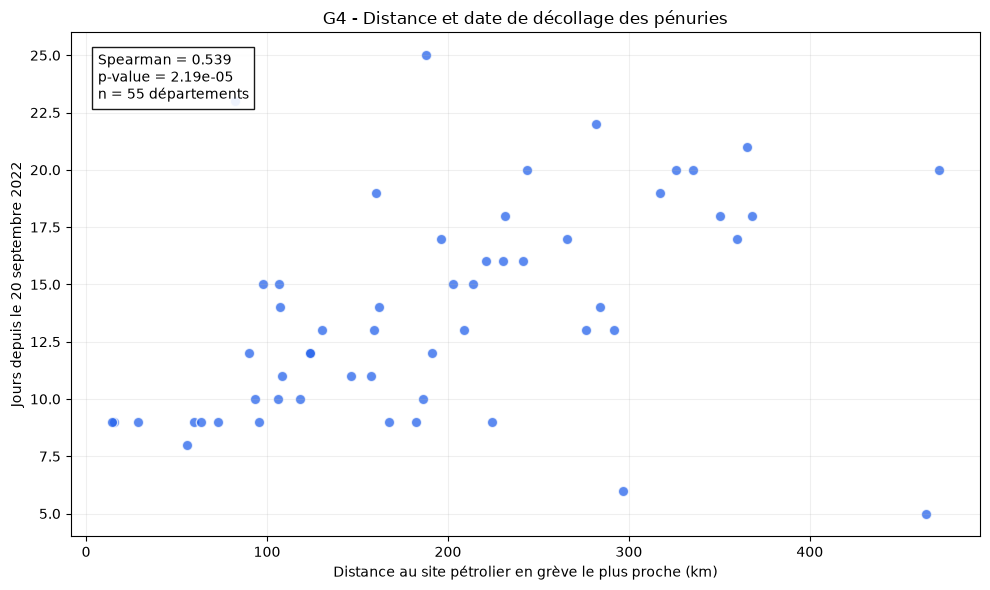

Graphique G4 et données enregistrés !


In [31]:

import matplotlib.pyplot as plt
from pathlib import Path

# Graphique final G4
fig, ax = plt.subplots(figsize=(10, 6))

ax.scatter(
    g4_valides["distance_km"],
    g4_valides["jour_decollage"],
    color="#2563EB",
    s=55,
    alpha=0.75,
    edgecolors="white"
)

ax.set_xlabel(
    "Distance au site pétrolier en grève le plus proche (km)"
)
ax.set_ylabel(
    "Jours depuis le 20 septembre 2022"
)

ax.set_title(
    "G4 - Distance et date de décollage des pénuries"
)

ax.text(
    0.03, 0.96,
    f"Spearman = {rho:.3f}\n"
    f"p-value = {pvalue:.2e}\n"
    f"n = {len(g4_valides)} départements",
    transform=ax.transAxes,
    va="top",
    bbox=dict(facecolor="white", alpha=0.9)
)

ax.grid(alpha=0.2)
plt.tight_layout()

# Enregistrer le graphique et les données
Path("resultats").mkdir(exist_ok=True)

fig.savefig(
    "resultats/G4_distance_decollage.png",
    dpi=300,
    bbox_inches="tight"
)

g4_valides.to_csv(
    "resultats/G4_donnees.csv",
    index=False
)

plt.show()

print("Graphique G4 et données enregistrés !")


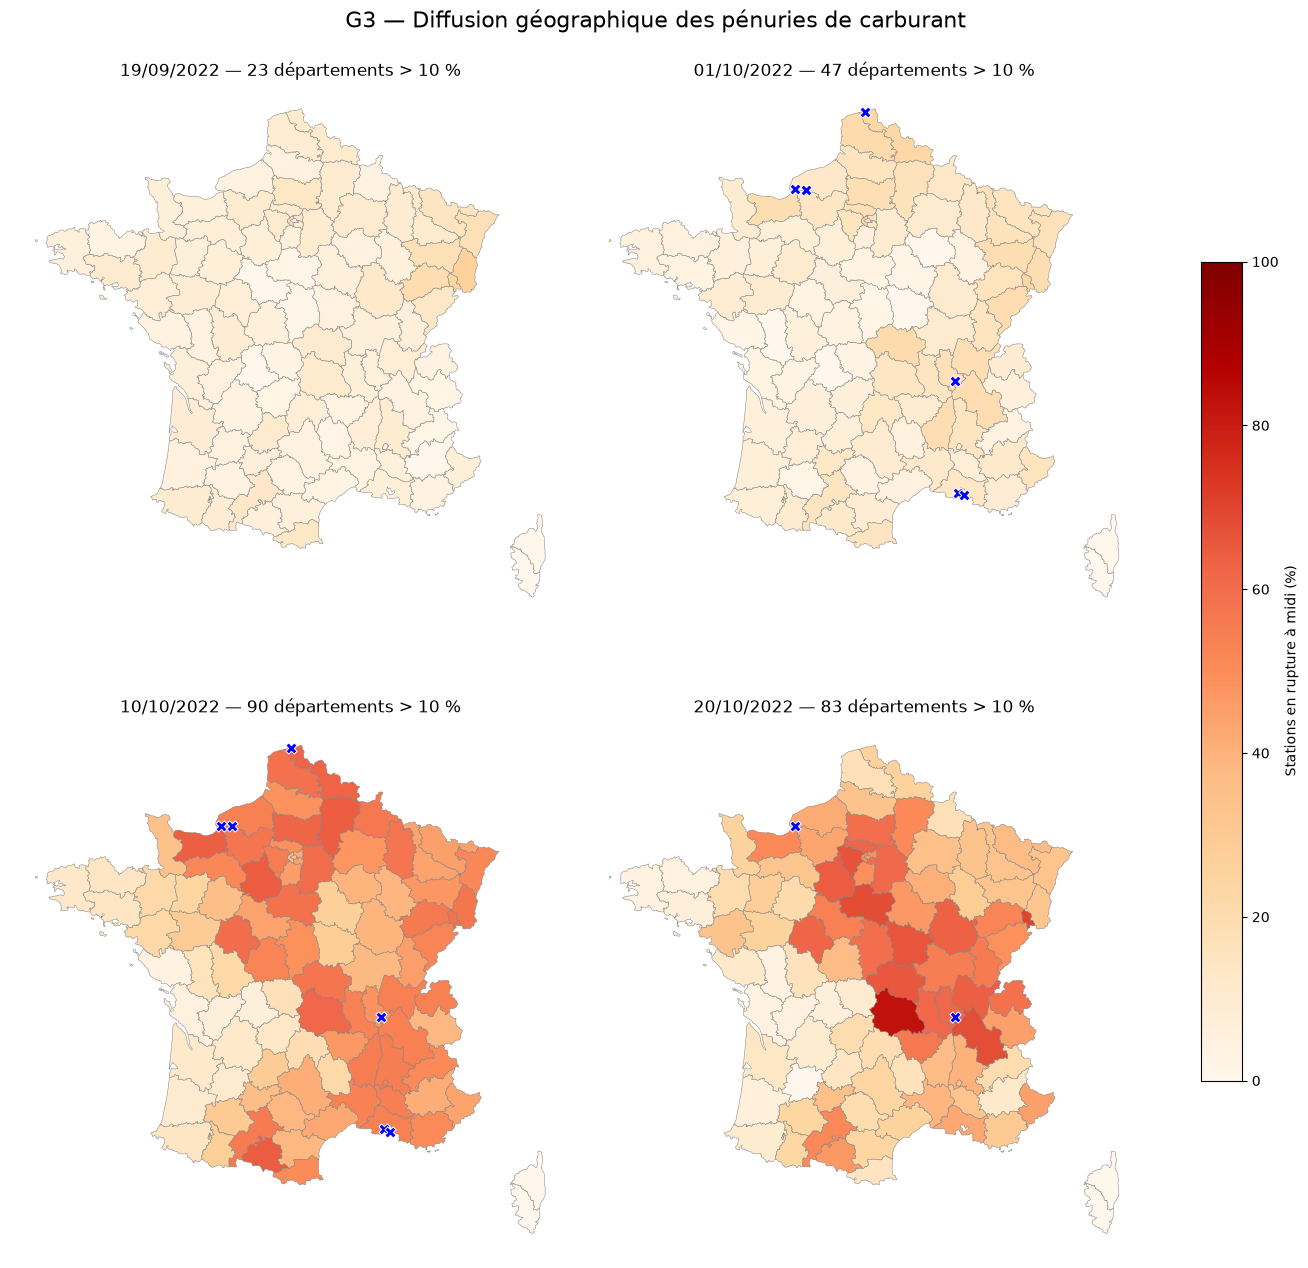

G3 enregistré !


In [32]:

import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import urllib.request
import json
from pathlib import Path

# Charger les contours des départements français
url = (
    "https://raw.githubusercontent.com/gregoiredavid/"
    "france-geojson/master/"
    "departements-version-simplifiee.geojson"
)

with urllib.request.urlopen(url) as response:
    geojson = json.load(response)

departements = gpd.GeoDataFrame.from_features(
    geojson["features"], crs="EPSG:4326"
)[["code", "geometry"]]

departements["code"] = departements["code"].astype(str)

# Les 4 dates retenues pour G3
dates = [
    "2022-09-19",
    "2022-10-01",
    "2022-10-10",
    "2022-10-20"
]

fig, axes = plt.subplots(
    2, 2, figsize=(13, 13),
    constrained_layout=True
)

cmap = "OrRd"

for ax, date in zip(axes.flat, dates):

    jour = pd.Timestamp(date)

    # Proportion de stations en rupture par département
    taux = (
        taux_departements.loc[jour]
        .rename("taux_rupture")
        .rename_axis("code")
        .reset_index()
    )

    carte = departements.merge(
        taux, on="code", how="left"
    )

    # Colorier les départements
    carte.plot(
        column="taux_rupture",
        ax=ax,
        cmap=cmap,
        vmin=0,
        vmax=100,
        edgecolor="grey",
        linewidth=0.35,
        missing_kwds={"color": "lightgrey"}
    )

    # Sites pétroliers en grève à cette date
    actifs = sites[
        (sites["debut_greve"] <= jour)
        & (sites["fin_greve"] >= jour)
    ]

    ax.scatter(
        actifs["longitude"],
        actifs["latitude"],
        color="blue",
        marker="X",
        s=65,
        edgecolors="white",
        linewidths=0.7,
        zorder=5
    )

    ax.set_title(
        jour.strftime("%d/%m/%Y")
        + f" — {int((taux['taux_rupture'] > 10).sum())}"
          " départements > 10 %",
        fontsize=12
    )

    ax.set_axis_off()

# Échelle commune aux quatre cartes
norm = mpl.colors.Normalize(vmin=0, vmax=100)
mappable = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)

fig.colorbar(
    mappable,
    ax=axes.ravel().tolist(),
    shrink=0.65,
    label="Stations en rupture à midi (%)"
)

fig.suptitle(
    "G3 — Diffusion géographique des pénuries de carburant",
    fontsize=16
)

# Enregistrement
Path("resultats").mkdir(exist_ok=True)

fig.savefig(
    "resultats/G3_cartes_diffusion.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("G3 enregistré !")


In [33]:

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED

# Sauvegarder les taux départementaux de G3
taux_departements.to_csv(
    "resultats/G3_taux_departements.csv",
    index_label="date"
)

# Fichiers nécessaires à la livraison
fichiers = [
    Path("verification_stations.ipynb"),
    Path("resultats/G3_cartes_diffusion.png"),
    Path("resultats/G3_taux_departements.csv"),
    Path("resultats/G4_distance_decollage.png"),
    Path("resultats/G4_donnees.csv")
]

manquants = [str(f) for f in fichiers if not f.is_file()]
if manquants:
    raise FileNotFoundError(f"Fichiers manquants : {manquants}")

with ZipFile("livrables_mercredi_G3_G4.zip", "w", ZIP_DEFLATED) as archive:
    for fichier in fichiers:
        archive.write(fichier)

print("Archive prête pour GitHub !")
print("Fichiers inclus :", len(fichiers))


Archive prête pour GitHub !
Fichiers inclus : 5
